# Exploring multimodal fusion-type transformer models for VQA

In [1]:
import torch
import numpy as np
import pandas as pd
import transformers
import os
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from PIL import Image
from torch import nn
from tqdm import tqdm
from datasets import load_dataset
from torchvision import transforms, models
from transformers import BertTokenizer

# About Dataset

VQA is a multimodal task wherein, given an image and a natural language question related to the image, the objective is to produce a natural language answer correctly as output.

It involves understanding the content of the image and correlating it with the context of the question asked. Because we need to compare the semantics of information present in both of the modalities — the image and natural language question related to it — VQA entails a wide range of sub-problems in both CV and NLP (such as object detection and recognition, scene classification, counting, and so on). Thus, it is considered an AI-complete task.

In [2]:
# DON'T CHANGE, FOR FAIR EVALUATION
import kagglehub
import os
import torchvision.transforms.functional as F
import shutil

# Download latest version
path = kagglehub.dataset_download("bhavikardeshna/visual-question-answering-computer-vision-nlp")

print("Path to dataset files:", path)

eval_data = pd.read_csv(os.path.join(path, "dataset", "data_eval.csv"))
mid = len(eval_data) // 2
data_eval = eval_data.iloc[:mid].reset_index(drop=True)
data_test = eval_data.iloc[mid:].reset_index(drop=True)
os.makedirs("dataset", exist_ok=True)
data_eval.to_csv(os.path.join(".", "dataset", "data_eval.csv"), index=False)
data_test.to_csv(os.path.join(".", "dataset", "data_test.csv"), index=False)
shutil.copy(os.path.join(path, "dataset", "answer_space.txt"), os.path.join("dataset", "answer_space.txt"))

Path to dataset files: /kaggle/input/datasets/bhavikardeshna/visual-question-answering-computer-vision-nlp


'dataset/answer_space.txt'

# About this directory

## Content

This dataset contains the processed DAQUAR Dataset (full), along with some of the raw files from the original dataset.

### Processed data:
- data.csv: This is the processed dataset after normalizing all the questions & converting the {question, answer, image_id} data into a tabular format for easier consumption.
- data_train.csv: This contains those records from data.csv which correspond to images present in train_images_list.txt
- data_eval.csv: This contains those records from data.csv which correspond to images present in test_images_list.txt
- data_test.csv: This contains those records from data.csv which correspond to images present in test_images_list.txt
- answer_space.txt: This file contains a list of all possible answers extracted from all_qa_pairs.txt (This will allow the VQA task to be modeled as a multi-class classification problem)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [4]:
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

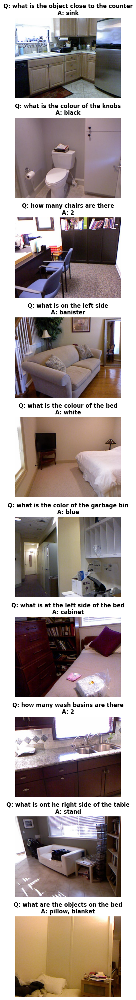

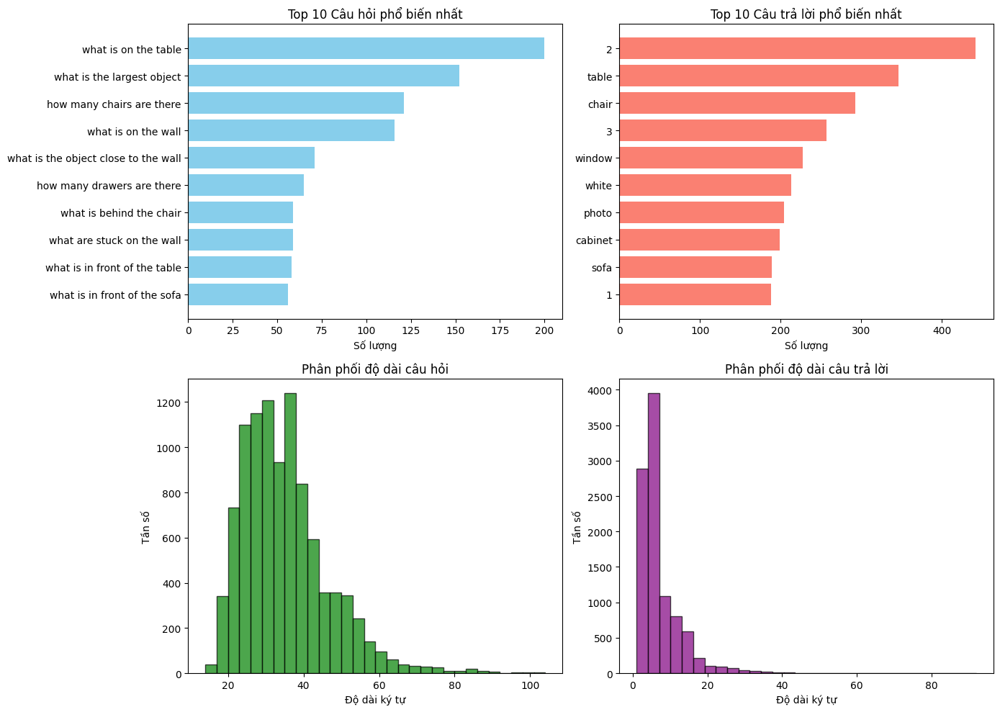

Tổng số mẫu: 9974
Số câu hỏi duy nhất: 4961
Số câu trả lời duy nhất: 1260
Độ dài trung bình câu hỏi: 34.59
Độ dài trung bình câu trả lời: 7.42


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
import cv2
import numpy as np
from collections import Counter

def full_vqa_visualization(csv_path, image_folder, num_samples=10):
    df = pd.read_csv(csv_path)
    
    if df.empty:
        print("File CSV rỗng")
        return

    sample_indices = random.sample(range(len(df)), min(num_samples, len(df)))
    
    fig, axes = plt.subplots(len(sample_indices), 1, figsize=(15, 3 * len(sample_indices)))
    if len(sample_indices) == 1:
        axes = [axes]
        
    valid_count = 0
    for i, idx in enumerate(sample_indices):
        row = df.iloc[idx]
        image_path = f"{image_folder}/{row['image_id']}.png"
        
        try:
            img = cv2.imread(image_path)
            if img is None:
                continue
            
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            axes[i].imshow(img)
            axes[i].set_title(f"Q: {row['question']}\nA: {row['answer']}", fontsize=12, fontweight='bold')
            axes[i].axis('off')
            valid_count += 1
        except Exception:
            continue
            
    if valid_count == 0:
        print("Không thể hiển thị ảnh. Kiểm tra đường dẫn folder ảnh.")
        plt.close()
        return
        
    plt.tight_layout()
    plt.show()

def analyze_vqa_distribution(csv_path):
    df = pd.read_csv(csv_path)
    
    q_counts = Counter(df['question'])
    a_counts = Counter(df['answer'])
    
    q_len = df['question'].str.len()
    a_len = df['answer'].str.len()
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # Top 10 Questions
    q_top = q_counts.most_common(10)
    q_labels = [x[0] for x in q_top]
    q_vals = [x[1] for x in q_top]
    axes[0, 0].barh(q_labels, q_vals, color='skyblue')
    axes[0, 0].set_title('Top 10 Câu hỏi phổ biến nhất')
    axes[0, 0].set_xlabel('Số lượng')
    axes[0, 0].invert_yaxis()
    
    # Top 10 Answers
    a_top = a_counts.most_common(10)
    a_labels = [x[0] for x in a_top]
    a_vals = [x[1] for x in a_top]
    axes[0, 1].barh(a_labels, a_vals, color='salmon')
    axes[0, 1].set_title('Top 10 Câu trả lời phổ biến nhất')
    axes[0, 1].set_xlabel('Số lượng')
    axes[0, 1].invert_yaxis()
    
    # Question Length Distribution
    axes[1, 0].hist(q_len, bins=30, color='green', alpha=0.7, edgecolor='black')
    axes[1, 0].set_title('Phân phối độ dài câu hỏi')
    axes[1, 0].set_xlabel('Độ dài ký tự')
    axes[1, 0].set_ylabel('Tần số')
    
    # Answer Length Distribution
    axes[1, 1].hist(a_len, bins=30, color='purple', alpha=0.7, edgecolor='black')
    axes[1, 1].set_title('Phân phối độ dài câu trả lời')
    axes[1, 1].set_xlabel('Độ dài ký tự')
    axes[1, 1].set_ylabel('Tần số')
    
    plt.tight_layout()
    plt.show()
    
    print(f"Tổng số mẫu: {len(df)}")
    print(f"Số câu hỏi duy nhất: {df['question'].nunique()}")
    print(f"Số câu trả lời duy nhất: {df['answer'].nunique()}")
    print(f"Độ dài trung bình câu hỏi: {q_len.mean():.2f}")
    print(f"Độ dài trung bình câu trả lời: {a_len.mean():.2f}")

csv_path='/kaggle/input/datasets/bhavikardeshna/visual-question-answering-computer-vision-nlp/dataset/data_train.csv'
image_path='/kaggle/input/datasets/bhavikardeshna/visual-question-answering-computer-vision-nlp/dataset/images'
full_vqa_visualization(csv_path,image_path)
analyze_vqa_distribution(csv_path)

In [6]:
import re
class VQADataset(Dataset):
    def __init__(self, csv_file, image_folder, cache_data_path, transform=None):
        self.image_folder = image_folder
        self.cache_data_path = cache_data_path
        self.transform = transform
        self.tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
        self.csv_file = csv_file
        self.preprocess_dataset()

    def clean_question(self, text):
        """Hàm tiền xử lý văn bản cho câu hỏi"""
        if not isinstance(text, str):
            return ""
        
        # Chuyển về chữ thường
        text = text.lower()
        
        # Thay thế các ký tự đặc biệt bằng dấu cách (trừ dấu chấm hỏi)
        text = re.sub(r'[^\w\s?]', ' ', text)
        
        # Xóa khoảng trắng thừa
        text = re.sub(r'\s+', ' ', text).strip()
        
        return text

    def preprocess_dataset(self):
        dataset_path = os.path.join(self.cache_data_path, "dataset")
        # Load dữ liệu từ CSV
        dataset = load_dataset(
            "csv",
            data_files={
                "fn": os.path.join(dataset_path, self.csv_file),
            }
        )

        # Đọc danh sách đáp án
        answer_path = os.path.join(dataset_path, "answer_space.txt")
        if os.path.exists(answer_path):
            with open(answer_path) as f:
                answer_space = f.read().splitlines()
        else:
            answer_space = []

        # Bước 1: Preprocess column 'question'
        dataset = dataset.map(
            lambda examples: {
                'question': [self.clean_question(q) for q in examples['question']]
            },
            batched=True
        )

        # Bước 2: Tạo nhãn (Label)
        dataset = dataset.map(
            lambda examples: {
                'label': [
                    answer_space.index(ans.replace(" ", "").split(",")[0])
                    if ans.replace(" ", "").split(",")[0] in answer_space else -1
                    for ans in examples['answer']
                ]
            },
            batched=True
        )

        # Chuyển sang DataFrame để dễ index
        self.data = pd.DataFrame(dataset['fn'])

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        image_id = row['image_id']
        question = row['question']
        answer = row['answer']
        
        image_path = os.path.join(self.image_folder, f"{image_id}.png")
        image = Image.open(image_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
        
        return image, question, answer

In [7]:
def get_vqa_transforms(is_train=True):
    if is_train:
        return transforms.Compose([
            # 1. Resize & Crop: Giữ tỷ lệ và cắt ngẫu nhiên
            transforms.Resize((256, 256)),  # Resize to larger size first
            transforms.RandomCrop(224),     # Random crop to 224x224
            transforms.RandomHorizontalFlip(p=0.5), 
            # transforms.ColorJitter(
            #     brightness=0.2, 
            #     contrast=0.2, 
            #     saturation=0.2, 
            #     hue=0.1
            # ),
            # transforms.RandomGrayscale(p=0.1), # Chuyển sang xám ngẫu nhiên
           
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])
    else:
        return transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.CenterCrop(224),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

# Sử dụng
train_transform = get_vqa_transforms(is_train=True)
val_transform = get_vqa_transforms(is_train=False)
dataset_path = os.path.join(path, "dataset")
# train_data_path = os.path.join(dataset_path, "data_train.csv")
# eval_data_path = os.path.join("dataset", "data_eval.csv")
images_path = os.path.join(dataset_path, "images")
train_dataset = VQADataset("data_train.csv", images_path, path, train_transform)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, pin_memory=True)
val_dataset = VQADataset("data_eval.csv", images_path, ".", val_transform)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False,  pin_memory=True)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Generating fn split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/9974 [00:00<?, ? examples/s]

Map:   0%|          | 0/9974 [00:00<?, ? examples/s]

Generating fn split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/1247 [00:00<?, ? examples/s]

Map:   0%|          | 0/1247 [00:00<?, ? examples/s]

Image ID : image1004
Question : what is available in the middle of the door
Answers :
  1. glass_pane


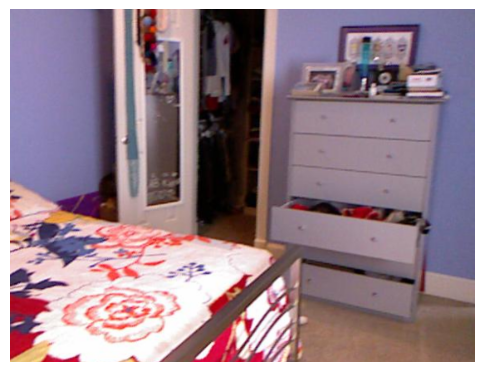

Image ID : image1142
Question : what is in between the bed and sofa
Answers :
  1. table


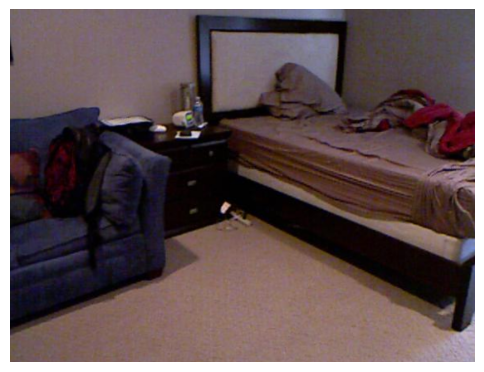

Image ID : image780
Question : how many colours fully displayed in doll
Answers :
  1. 3


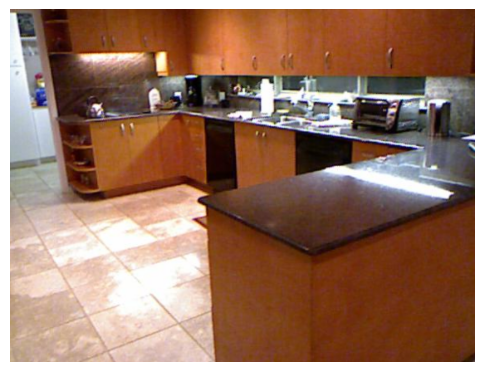

Image ID : image912
Question : what is on the right side of the door
Answers :
  1. television


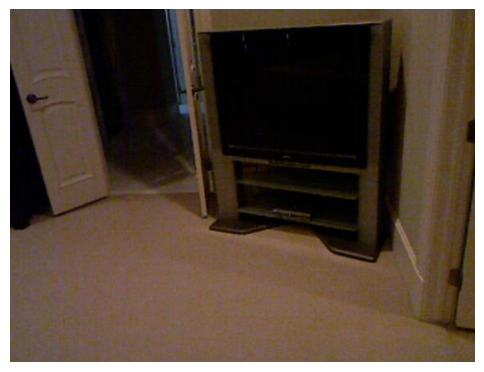

Image ID : image430
Question : what is on the right side of the chess board
Answers :
  1. remote_control


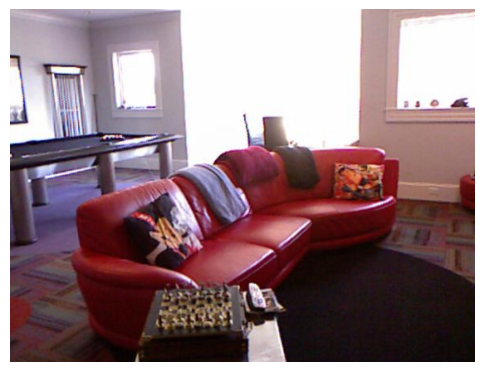

Image ID : image1398
Question : what is behind the chair
Answers :
  1. table
  2. drawer


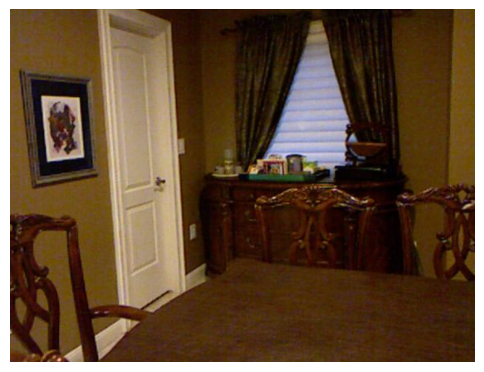

Image ID : image352
Question : what is to the right of the stairs
Answers :
  1. sofa


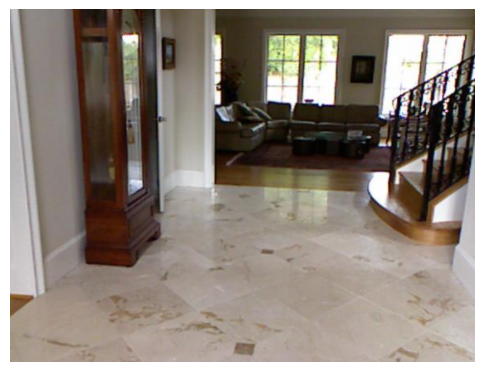

Image ID : image867
Question : what is the object close to the wall above the stove
Answers :
  1. microwave


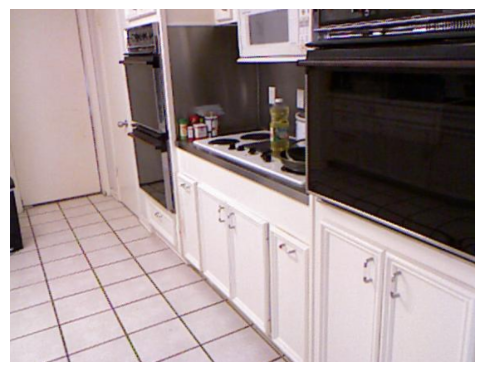

Image ID : image1039
Question : what is attached to the bunk bed
Answers :
  1. slide


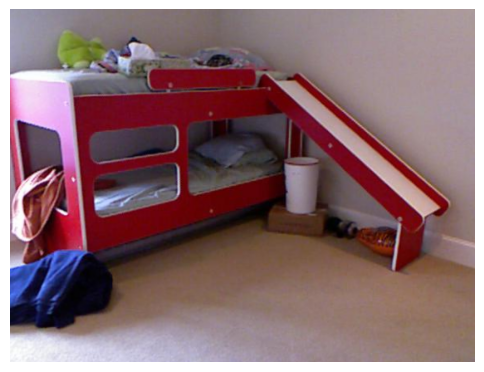

Image ID : image242
Question : what is in front of the sofa
Answers :
  1. table


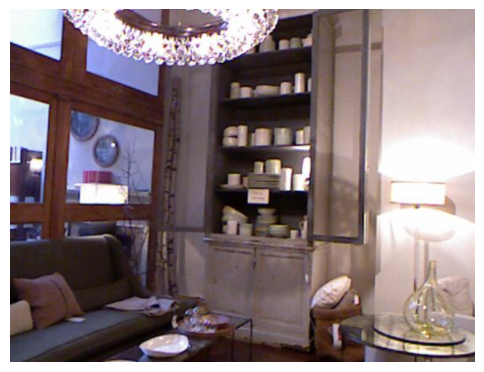

In [8]:
import matplotlib.pyplot as plt
import random
from PIL import Image
import os

def visualize_samples(dataset, num_samples=5):

    indices = random.sample(range(len(dataset)), num_samples)

    for idx in indices:

        row = dataset.data.iloc[idx]

        image_id = row['image_id']

        question = row['question']

        answer = row['answer']

        image_path = os.path.join(
            dataset.image_folder,
            f"{image_id}.png"
        )

        image = Image.open(image_path).convert("RGB")

        plt.figure(figsize=(6, 6))
        plt.imshow(image)
        plt.axis("off")

        print("=" * 80)
        print(f"Image ID : {image_id}")
        print(f"Question : {question}")

        if isinstance(answer, str):

            answers = [
                a.strip()
                for a in answer.split(",")
            ]

            print("Answers :")

            for i, a in enumerate(answers):

                print(f"  {i+1}. {a}")

        else:

            print(f"Answer : {answer}")

        plt.show()


visualize_samples(train_dataset, 10)

In [9]:
import torch
import torch.nn as nn
from transformers import BertModel
from torchvision import models
from torch.cuda.amp import autocast, GradScaler
from torch.utils.checkpoint import checkpoint
from tqdm import tqdm
import matplotlib.pyplot as plt
import json

from transformers import BlipProcessor, BlipForQuestionAnswering

class BLIPVQAModel(nn.Module):

    def __init__(self):

        super().__init__()

        self.processor = BlipProcessor.from_pretrained(
            "Salesforce/blip-vqa-base"
        )

        self.model = BlipForQuestionAnswering.from_pretrained(
            "Salesforce/blip-vqa-base"
        )

    def forward(self, images, questions, answers=None):

        device = next(self.model.parameters()).device

        inputs = self.processor(
            images=images,
            text=questions,
            padding=True,
            truncation=True,
            return_tensors="pt"
        )

        inputs = {k: v.to(device) for k, v in inputs.items()}

        if answers is not None:

            labels = self.processor.tokenizer(
                answers,
                padding=True,
                truncation=True,
                return_tensors="pt"
            ).input_ids.to(device)

            outputs = self.model(
                **inputs,
                labels=labels
            )

            return outputs.loss

        else:

            outputs = self.model.generate(
                **inputs,
                max_new_tokens=10
            )

            preds = self.processor.batch_decode(
                outputs,
                skip_special_tokens=True
            )

            return preds

In [10]:
import torch.optim as optim
from torch.nn import CrossEntropyLoss

model = BLIPVQAModel()
model.to(device)

num_epochs = 5
lr = 1e-5
weight_decay = 1e-4
best_loss = float('inf')
best_model_state = None
patience = 10  
early_stopping_counter = 0

for layer in model.model.vision_model.encoder.layers[:8]:
    for p in layer.parameters():
        p.requires_grad = False
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=weight_decay)
scaler = GradScaler() 

criterion = nn.CrossEntropyLoss()

import torch.optim.lr_scheduler as lr_scheduler

class LinearWarmupCosineAnnealingLR(lr_scheduler._LRScheduler):
    def __init__(self, optimizer, T_max, warmup_steps, eta_min=0, last_epoch=-1):
        self.T_max = T_max
        self.warmup_steps = warmup_steps
        self.eta_min = eta_min
        
        super().__init__(optimizer, last_epoch=last_epoch)

    def get_lr(self):
        if self.last_epoch < self.warmup_steps:
            return [
                base_lr * (self.last_epoch + 1) / self.warmup_steps 
                for base_lr in self.base_lrs
            ]
        else:
            current_step = self.last_epoch - self.warmup_steps
            total_cosine_steps = self.T_max - self.warmup_steps
            lrs = [
                base_lr * 0.5 * (1 + torch.cos(
                    torch.pi * current_step / total_cosine_steps
                )) + self.eta_min
                for base_lr in self.base_lrs
            ]
            return lrs

scheduler = LinearWarmupCosineAnnealingLR(
    optimizer=optimizer, 
    T_max=100,         
    warmup_steps=10,    
    eta_min=0,
    last_epoch=-1,
)


preprocessor_config.json:   0%|          | 0.00/445 [00:00<?, ?B/s]

The image processor of type `BlipImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.54G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/788 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
BlipForQuestionAnswering LOAD REPORT from: Salesforce/blip-vqa-base
Key                                       | Status     |  | 
------------------------------------------+------------+--+-
text_decoder.bert.embeddings.position_ids | UNEXPECTED |  | 
text_encoder.embeddings.position_ids      | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_22/1848532866.py:19: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


In [11]:
def calculate_accuracy(outputs, labels):
        _, preds = torch.max(outputs, 1)
        correct = (preds == labels).float().sum()
        accuracy = correct / labels.size(0)
        return accuracy.item()

In [12]:
import torch
from tqdm import tqdm

import torch
from tqdm import tqdm
from torch.cuda.amp import autocast

def calculate_accuracy(preds, answers):

    correct = 0

    for p, a in zip(preds, answers):

        p = str(p).strip().lower()
        a = str(a).strip().lower()

        if p == a:
            correct += 1

    return correct / len(preds)


def train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    scaler,
    device,
    num_epochs,
    patience,
    save_path
):

    train_losses = []
    val_losses = []

    train_accuracies = []
    val_accuracies = []

    best_loss = float('inf')

    early_stopping_counter = 0

    for epoch in range(num_epochs):

        model.train()

        running_loss = 0.0
        running_accuracy = 0.0

        progress_bar = tqdm(
            train_loader,
            desc=f"Epoch {epoch+1}/{num_epochs}",
            unit="batch"
        )

        for images, questions, answers in progress_bar:

            images = images.to(device)

            optimizer.zero_grad()

            with autocast():

                loss = model(images, questions, answers)

            scaler.scale(loss).backward()

            scaler.step(optimizer)

            scaler.update()

            running_loss += loss.item()

            with torch.no_grad():

                preds = model(images, questions)

                accuracy = calculate_accuracy(preds, answers)

            running_accuracy += accuracy

            progress_bar.set_postfix(
                loss=loss.item(),
                acc=accuracy
            )

        epoch_loss = running_loss / len(train_loader)
        epoch_accuracy = running_accuracy / len(train_loader)

        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)

        print({
            "train_loss": epoch_loss,
            "train_accuracy": epoch_accuracy,
            "epoch": epoch + 1
        })

        model.eval()

        val_running_loss = 0.0
        val_running_accuracy = 0.0

        with torch.no_grad():

            val_progress_bar = tqdm(
                val_loader,
                desc="Validating",
                unit="batch"
            )

            for images, questions, answers in val_progress_bar:

                images = images.to(device)

                with autocast():

                    loss = model(images, questions, answers)

                preds = model(images, questions)

                accuracy = calculate_accuracy(preds, answers)

                val_running_loss += loss.item()
                val_running_accuracy += accuracy

                val_progress_bar.set_postfix(
                    loss=loss.item(),
                    acc=accuracy
                )

        val_loss = val_running_loss / len(val_loader)
        val_accuracy = val_running_accuracy / len(val_loader)

        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        print({
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "epoch": epoch + 1
        })

        print(
            f"Epoch {epoch+1}/{num_epochs} | "
            f"Train Loss: {epoch_loss:.4f} | "
            f"Train Acc: {epoch_accuracy:.4f}"
        )

        print(
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

        if val_loss < best_loss:

            best_loss = val_loss

            early_stopping_counter = 0

            print(f"Saving best model: {best_loss:.4f}")

            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scaler_state_dict': scaler.state_dict(),
                'best_loss': best_loss,
                'train_losses': train_losses,
                'val_losses': val_losses,
                'train_accuracies': train_accuracies,
                'val_accuracies': val_accuracies
            }, save_path)

        else:

            early_stopping_counter += 1

            print(
                f"No improvement for "
                f"{early_stopping_counter} epochs"
            )

        if early_stopping_counter >= patience:

            print("Early stopping triggered")

            break

    metrics = {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accuracies": train_accuracies,
        "val_accuracies": val_accuracies
    }

    return metrics


def evaluate_model(
    model,
    data_loader,
    device
):

    model.eval()

    running_loss = 0.0
    running_accuracy = 0.0

    with torch.no_grad():

        progress_bar = tqdm(
            data_loader,
            desc="Evaluating",
            unit="batch"
        )

        for images, questions, answers in progress_bar:

            images = images.to(device)

            with autocast():

                loss = model(images, questions, answers)

            preds = model(images, questions)

            accuracy = calculate_accuracy(preds, answers)

            running_loss += loss.item()
            running_accuracy += accuracy

            progress_bar.set_postfix(
                loss=loss.item(),
                acc=accuracy
            )

    loss = running_loss / len(data_loader)
    accuracy = running_accuracy / len(data_loader)

    print(f"Loss: {loss:.4f}")
    print(f"Accuracy: {accuracy:.4f}")

    return loss, accuracy

In [13]:
import json

metrics = train_model(model, train_loader, val_loader,  optimizer, scaler, device, num_epochs, patience, "best_model.pth")
with open("metrics.json", "w") as f:
    json.dump(metrics, f)

Epoch 1/5:   0%|          | 0/624 [00:00<?, ?batch/s]/tmp/ipykernel_22/2423194783.py:64: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.
Epoch 1/5: 100%|██████████| 624/624 [21:38<00:00,  2.08s/batch, acc=0.167, loss=5.92]


{'train_loss': 6.9085179552053795, 'train_accuracy': 0.20078792735042736, 'epoch': 1}


Validating:   0%|          | 0/78 [00:00<?, ?batch/s]/tmp/ipykernel_22/2423194783.py:118: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Validating: 100%|██████████| 78/78 [01:49<00:00,  1.41s/batch, acc=0.0667, loss=7.43]


{'val_loss': 6.415911491100605, 'val_accuracy': 0.23723290598290597, 'epoch': 1}
Epoch 1/5 | Train Loss: 6.9085 | Train Acc: 0.2008
Val Loss: 6.4159 | Val Acc: 0.2372
Saving best model: 6.4159


Epoch 2/5: 100%|██████████| 624/624 [21:34<00:00,  2.07s/batch, acc=0.167, loss=5.72]


{'train_loss': 6.019335178228525, 'train_accuracy': 0.24686164529914528, 'epoch': 2}


Validating: 100%|██████████| 78/78 [01:49<00:00,  1.41s/batch, acc=0.133, loss=6.22]


{'val_loss': 5.733703399315859, 'val_accuracy': 0.24129273504273505, 'epoch': 2}
Epoch 2/5 | Train Loss: 6.0193 | Train Acc: 0.2469
Val Loss: 5.7337 | Val Acc: 0.2413
Saving best model: 5.7337


Epoch 3/5: 100%|██████████| 624/624 [21:37<00:00,  2.08s/batch, acc=0, loss=4.9]


{'train_loss': 5.405426559157861, 'train_accuracy': 0.26502403846153844, 'epoch': 3}


Validating: 100%|██████████| 78/78 [01:50<00:00,  1.41s/batch, acc=0.2, loss=5.14]


{'val_loss': 5.10765108695397, 'val_accuracy': 0.24775641025641024, 'epoch': 3}
Epoch 3/5 | Train Loss: 5.4054 | Train Acc: 0.2650
Val Loss: 5.1077 | Val Acc: 0.2478
Saving best model: 5.1077


Epoch 4/5: 100%|██████████| 624/624 [21:38<00:00,  2.08s/batch, acc=0.333, loss=4.19]


{'train_loss': 4.830587347348531, 'train_accuracy': 0.2797809829059829, 'epoch': 4}


Validating: 100%|██████████| 78/78 [01:50<00:00,  1.42s/batch, acc=0.133, loss=4.17]


{'val_loss': 4.5583664912443895, 'val_accuracy': 0.24930555555555556, 'epoch': 4}
Epoch 4/5 | Train Loss: 4.8306 | Train Acc: 0.2798
Val Loss: 4.5584 | Val Acc: 0.2493
Saving best model: 4.5584


Epoch 5/5: 100%|██████████| 624/624 [21:42<00:00,  2.09s/batch, acc=0.167, loss=2.02]


{'train_loss': 3.1148424244079833, 'train_accuracy': 0.2876268696581196, 'epoch': 5}


Validating: 100%|██████████| 78/78 [01:50<00:00,  1.42s/batch, acc=0.2, loss=2.21]


{'val_loss': 2.0518260567616196, 'val_accuracy': 0.2709935897435897, 'epoch': 5}
Epoch 5/5 | Train Loss: 3.1148 | Train Acc: 0.2876
Val Loss: 2.0518 | Val Acc: 0.2710
Saving best model: 2.0518


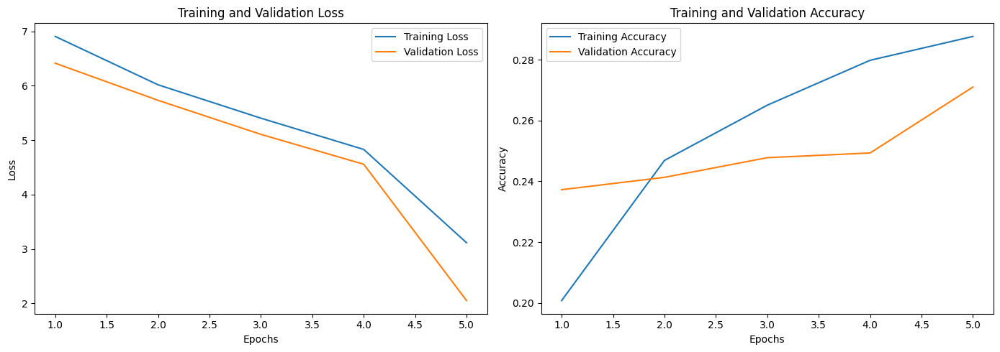

In [14]:
# Plot the result
# Load the saved metrics
with open("metrics.json", "r") as f:
    metrics = json.load(f)

train_losses = metrics["train_losses"]
val_losses = metrics["val_losses"]
train_accuracies = metrics["train_accuracies"]
val_accuracies = metrics["val_accuracies"]

# Plot the metrics
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label='Training Loss')
plt.plot(epochs, val_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')

plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, label='Training Accuracy')
plt.plot(epochs, val_accuracies, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')

plt.tight_layout()
plt.show()

## Testing Result

In [15]:
test_dataset = VQADataset("data_test.csv", images_path, ".", val_transform)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=4, pin_memory=True)
test_loss, test_accuracy = evaluate_model(model, test_loader,  device)

Generating fn split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/1247 [00:00<?, ? examples/s]

Map:   0%|          | 0/1247 [00:00<?, ? examples/s]

Evaluating:   0%|          | 0/20 [00:00<?, ?batch/s]/tmp/ipykernel_22/2423194783.py:225: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Evaluating: 100%|██████████| 20/20 [01:36<00:00,  4.81s/batch, acc=0.161, loss=2.13]

Loss: 2.0978
Accuracy: 0.2651


### Sample Generation for Method Revalidation


In [16]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sentence_transformers import SentenceTransformer, util

# Load Sentence-BERT model
model_sbert = SentenceTransformer('paraphrase-MiniLM-L6-v2')

# Function to calculate similarity using Sentence-BERT
def sbert_similarity(sentence1, sentence2):
    embeddings1 = model_sbert.encode(sentence1, convert_to_tensor=True)
    embeddings2 = model_sbert.encode(sentence2, convert_to_tensor=True)
    cosine_scores = util.pytorch_cos_sim(embeddings1, embeddings2)
    return cosine_scores.item()

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/paraphrase-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/314 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [17]:
def preprocess_answer(answer):
    # Remove underscores from the answer
    return answer.replace('_', ' ')

In [18]:
# Load answer space for mapping
with open(os.path.join(path, "dataset", "answer_space.txt")) as f:
    answer_space = f.read().splitlines()

model.eval()
test_losses = []
test_accuracies = []
similarities = []

criterion = nn.CrossEntropyLoss()

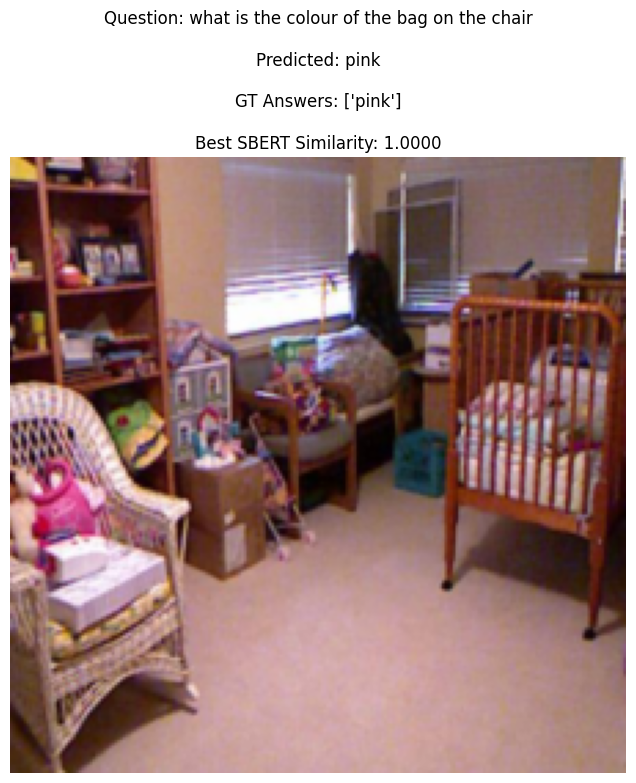

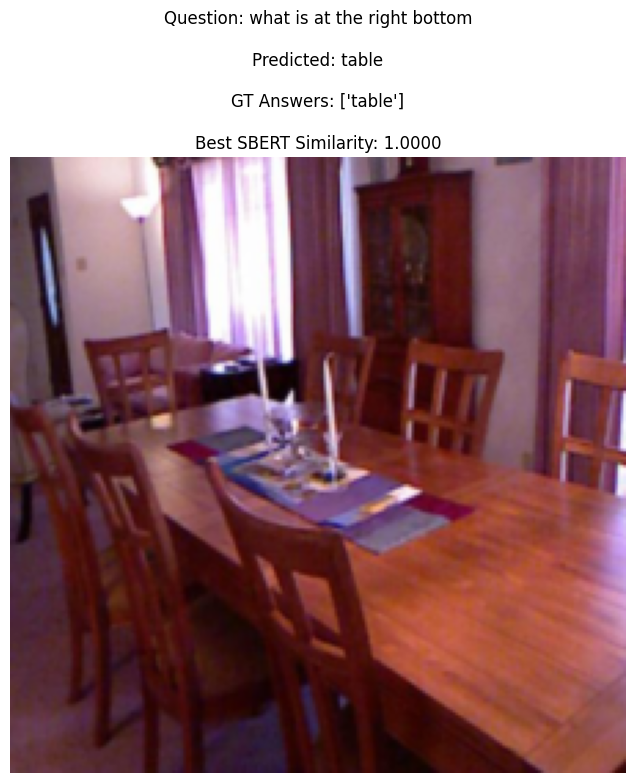

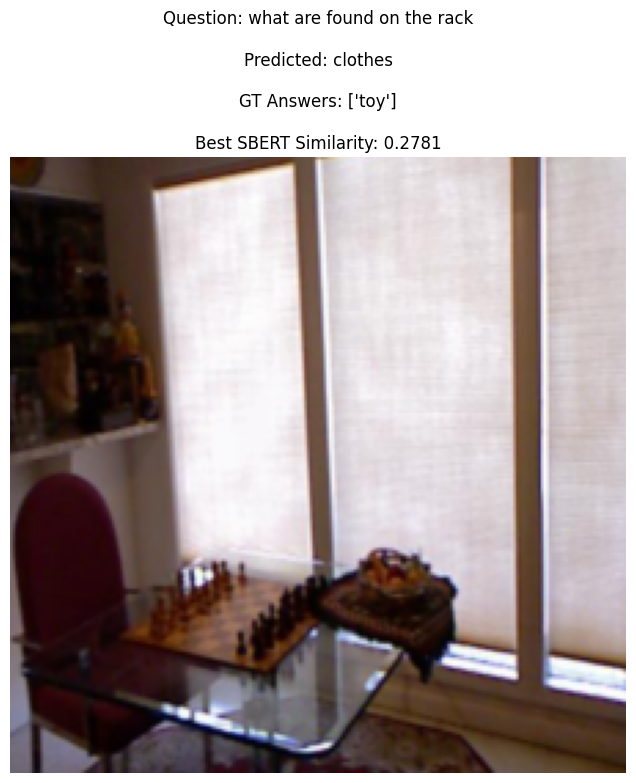

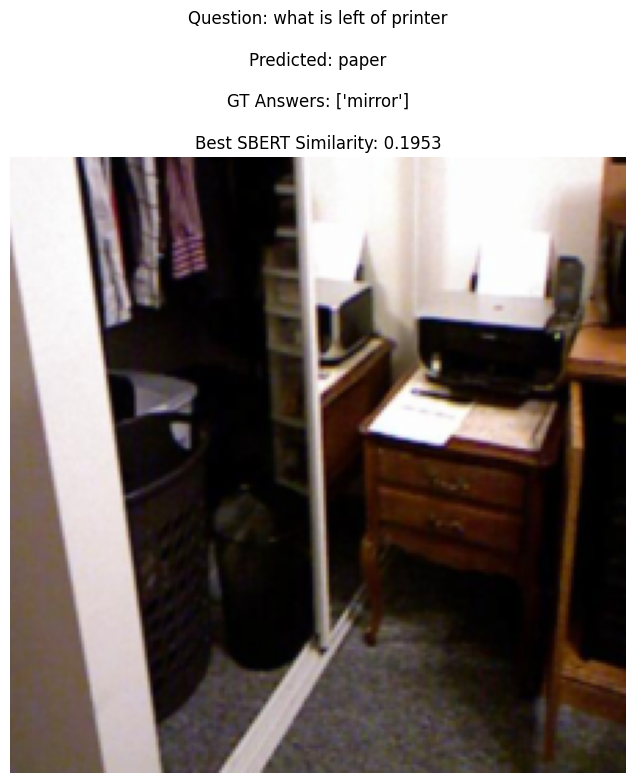

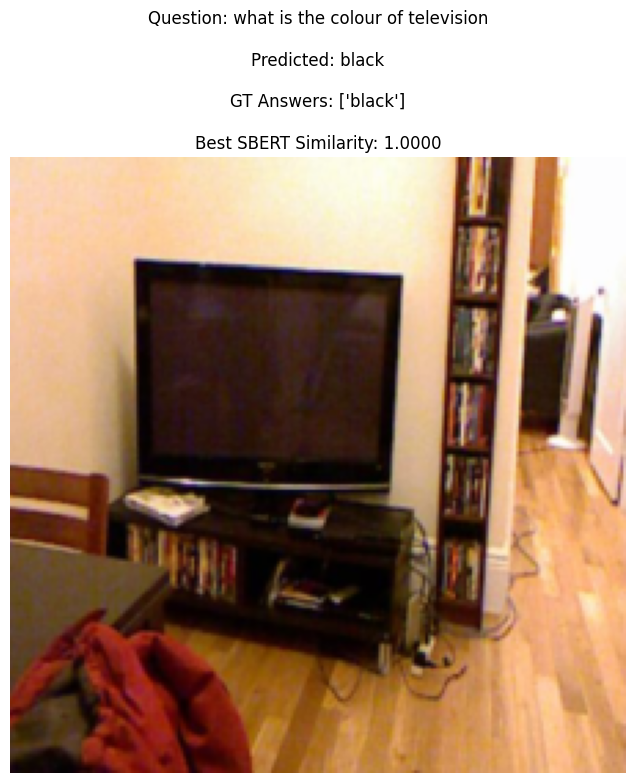

...

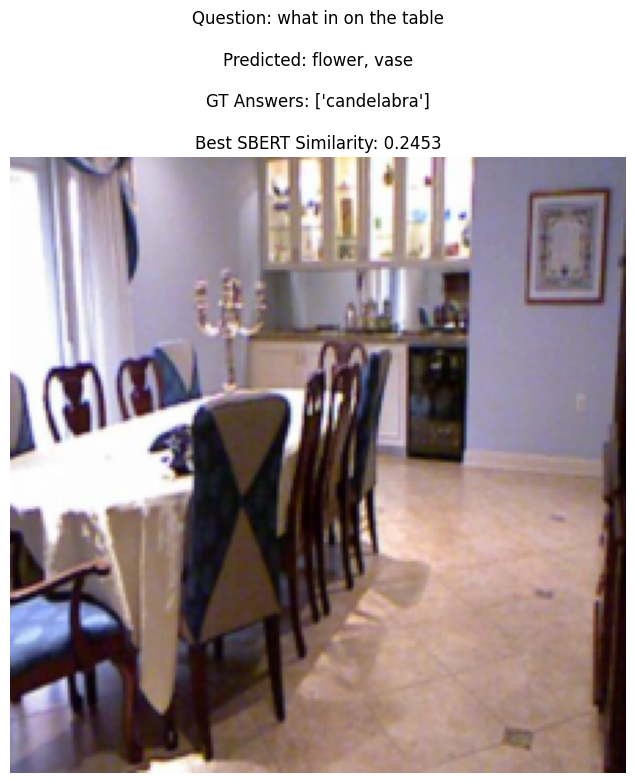

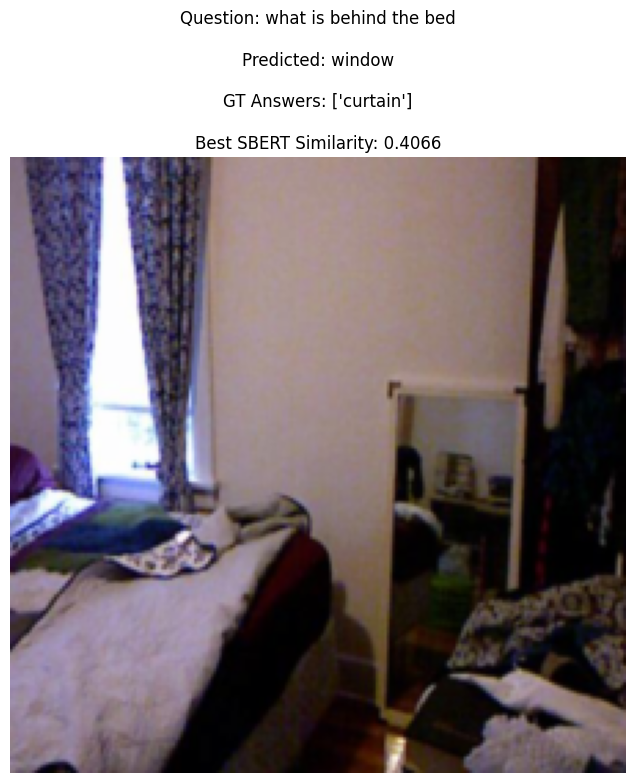

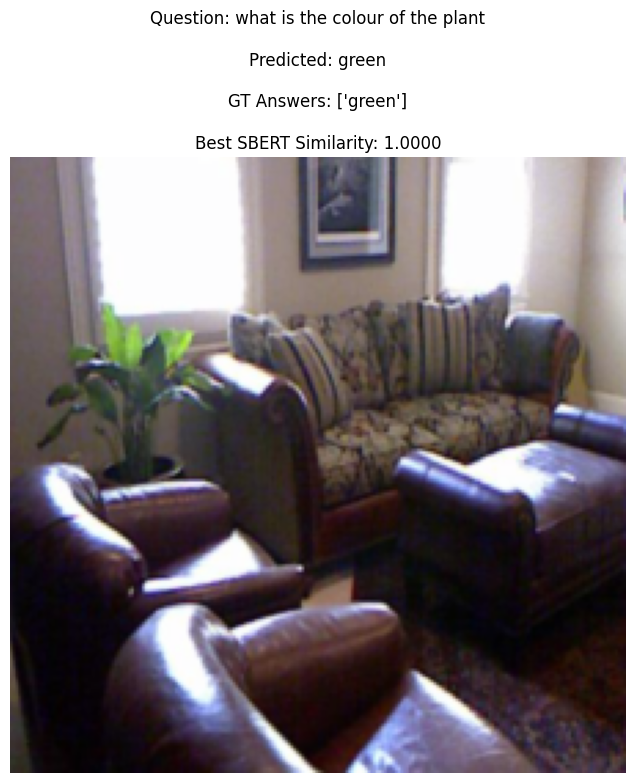

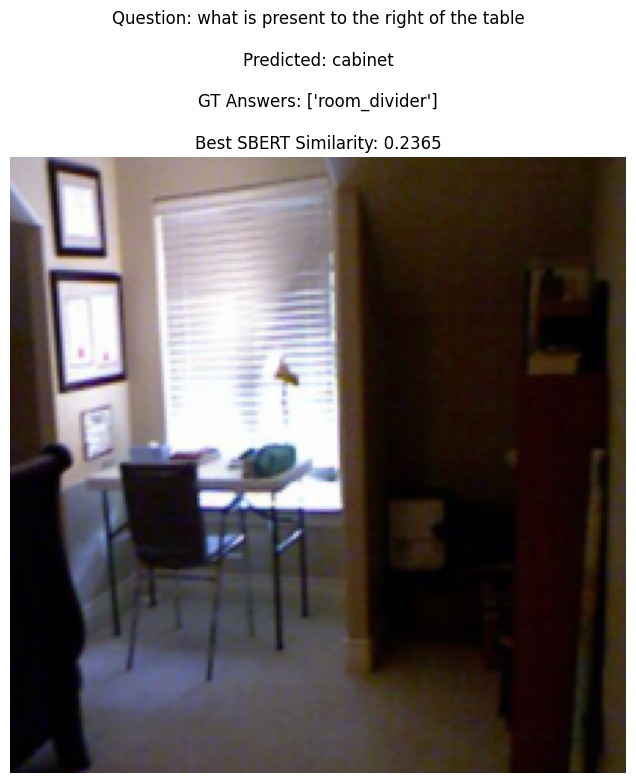

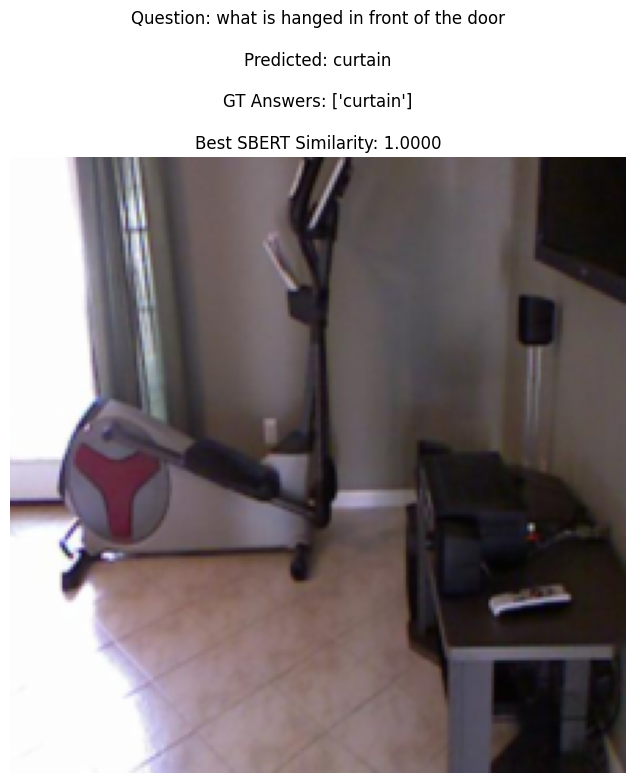

Average SBERT Similarity: 0.6674
Soft Accuracy: 0.4500


In [19]:

toy_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=1,
    pin_memory=True
)

model.eval()

similarities = []
test_accuracies = []

with torch.no_grad():

    for idx, (images, questions, answers) in enumerate(toy_loader):

        images = images.to(device)

        preds = model(images, questions)

        predicted_answer = str(preds[0]).strip().lower()

        actual_answers = [
            a.strip().lower()
            for a in answers[0].split(",")
        ]

        best_similarity = 0

        for gt in actual_answers:

            similarity = sbert_similarity(
                predicted_answer,
                gt
            )

            best_similarity = max(
                best_similarity,
                similarity
            )

        similarities.append(best_similarity)

        correct = 0

        for gt in actual_answers:

            if (
                gt in predicted_answer
                or
                predicted_answer in gt
            ):

                correct = 1
                break

        test_accuracies.append(correct)

        image = (
            images.cpu()
            .squeeze()
            .permute(1, 2, 0)
            .numpy()
        )

        image = (
            image * np.array([0.229, 0.224, 0.225])
            +
            np.array([0.485, 0.456, 0.406])
        )

        image = np.clip(image, 0, 1)

        plt.figure(figsize=(8, 8))

        plt.imshow(image)

        plt.title(
            f"Question: {questions[0]}\n\n"
            f"Predicted: {predicted_answer}\n\n"
            f"GT Answers: {actual_answers}\n\n"
            f"Best SBERT Similarity: {best_similarity:.4f}"
        )

        plt.axis('off')

        plt.show()

        if idx >= 19:
            break

average_similarity = np.mean(similarities)

average_accuracy = np.mean(test_accuracies)

print(f"Average SBERT Similarity: {average_similarity:.4f}")

print(f"Soft Accuracy: {average_accuracy:.4f}")

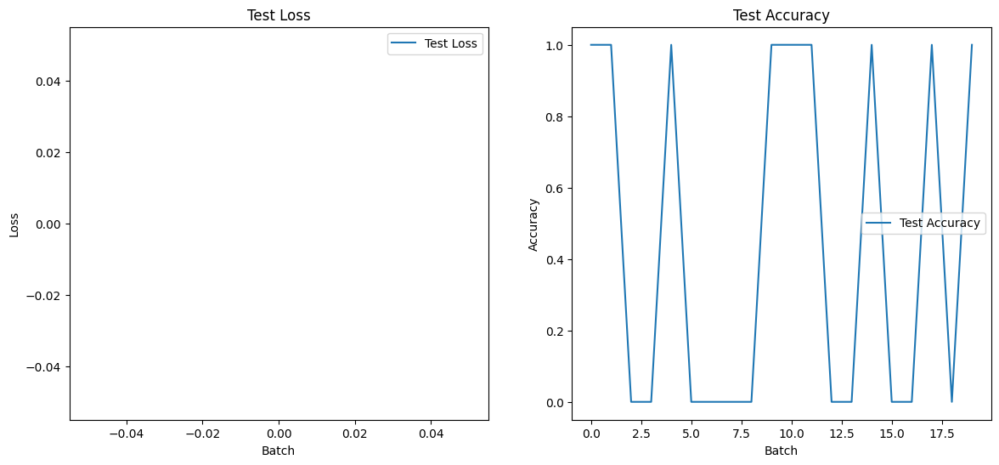

In [20]:
# Plot test accuracy and test loss
plt.figure(figsize=(14, 6))

# Test Loss
plt.subplot(1, 2, 1)
plt.plot(test_losses, label='Test Loss')
plt.xlabel('Batch')
plt.ylabel('Loss')
plt.title('Test Loss')
plt.legend()

# Test Accuracy
plt.subplot(1, 2, 2)
plt.plot(test_accuracies, label='Test Accuracy')
plt.xlabel('Batch')
plt.ylabel('Accuracy')
plt.title('Test Accuracy')
plt.legend()

plt.show()

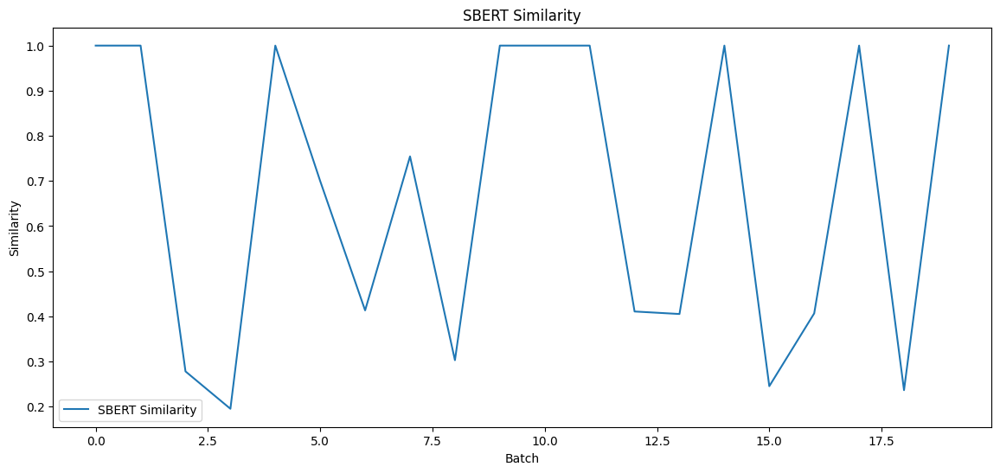

In [21]:
# Similarity
plt.figure(figsize=(14, 6))
plt.subplot(1, 1, 1)
plt.plot(similarities, label='SBERT Similarity')
plt.xlabel('Batch')
plt.ylabel('Similarity')
plt.title('SBERT Similarity')
plt.legend()
plt.show()